# Master Presentation Experiments & Plots (MTR L1-Aligned Pipeline)
## CENACE Monclova Load Zone — Real-Time Market (`MTR`) Modeling & Analytics

This self-contained master notebook generates **every verified number, statistical proof, model leaderboard, and presentation graphic** used in [`monclova_lmp_presentation.pptx`](../presentation/monclova_lmp_presentation.pptx), cleanly aligned to strictly causal **Real-Time Market (`pml_mtr`)** forecasting (`lag_1` is 100% causally valid at inference time) and **`HistGBDT (L1 / MAE Loss)`**.

### Key Architectural Framework
1. **Slide 2 — Fundamentals (`MDA vs. MTR` Basis Risk):** `slide_02_mtr_basis_premium.png`
2. **Slide 3 — Monclova Substation Grid Geography (9 Nodes):** `slide_03_spatial_grid_topology.png`
3. **Slide 5 — Market Physics & Unified Model Proof (`MTR`):** `slide_05_mtr_physics_and_coherence.png`
4. **Slide 6 — Temporal Intraday & Industrial Load Cycles (`MTR`):** `slide_06_mtr_temporal_dynamics.png`
5. **Slide 7 — 3-Model MTR Benchmark (`SARIMA`, `Ridge L2`, `HistGBDT L1`) & Track 2 Anomaly Summary**
6. **Slide 8 — Mechanistic Attribution (`Ridge Weights` vs `HistGBDT L1 Importance`):** `slide_08_mtr_feature_importance.png`
7. **Slide 9 — Algorithmic Failure Modes, Systematic Bias & Reliability CDF (`MTR`):**
   - `slide_09_mtr_bias_and_cdf.png`
   - `slide_10a_mtr_solar_overshoot.png`, `slide_10b_mtr_bias_curve.png`, `slide_10c_mtr_error_cdf.png`
8. **Slide 10 — Systemic Grid Stress & Track 2 Anomaly Detection (`MDA` Only):** `slide_11_anomaly_detection.png`


In [1]:
from pathlib import Path
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import contextily as cx

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import Ridge, HuberRegressor, SGDRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

CWD = Path.cwd().resolve()
PROJECT_ROOT = next(
    p for p in [CWD, *CWD.parents]
    if (p / 'data' / 'processed' / 'combined_monclova_lmp.parquet').exists()
)
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'combined_monclova_lmp.parquet'
FIG_DIR = PROJECT_ROOT / 'experiments' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.edgecolor'] = '#CBD5E1'

df = pd.read_parquet(DATA_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['clv_nodo', 'timestamp']).reset_index(drop=True)
df['dayofweek'] = df['timestamp'].dt.day_of_week
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

print(f"Loaded: {len(df):,} rows | Nodes: {df['clv_nodo'].nunique()} | Dates: {df['timestamp'].min()} -> {df['timestamp'].max()}")
print(f"MTR Mean: ${df['pml_mtr'].mean():.2f}, Median: ${df['pml_mtr'].median():.2f}, Min: ${df['pml_mtr'].min():.2f}, Max: ${df['pml_mtr'].max():.2f}")


Loaded: 118,152 rows | Nodes: 9 | Dates: 2024-01-01 00:00:00 -> 2025-06-30 23:00:00
MTR Mean: $813.37, Median: $541.03, Min: $20.96, Max: $12942.84


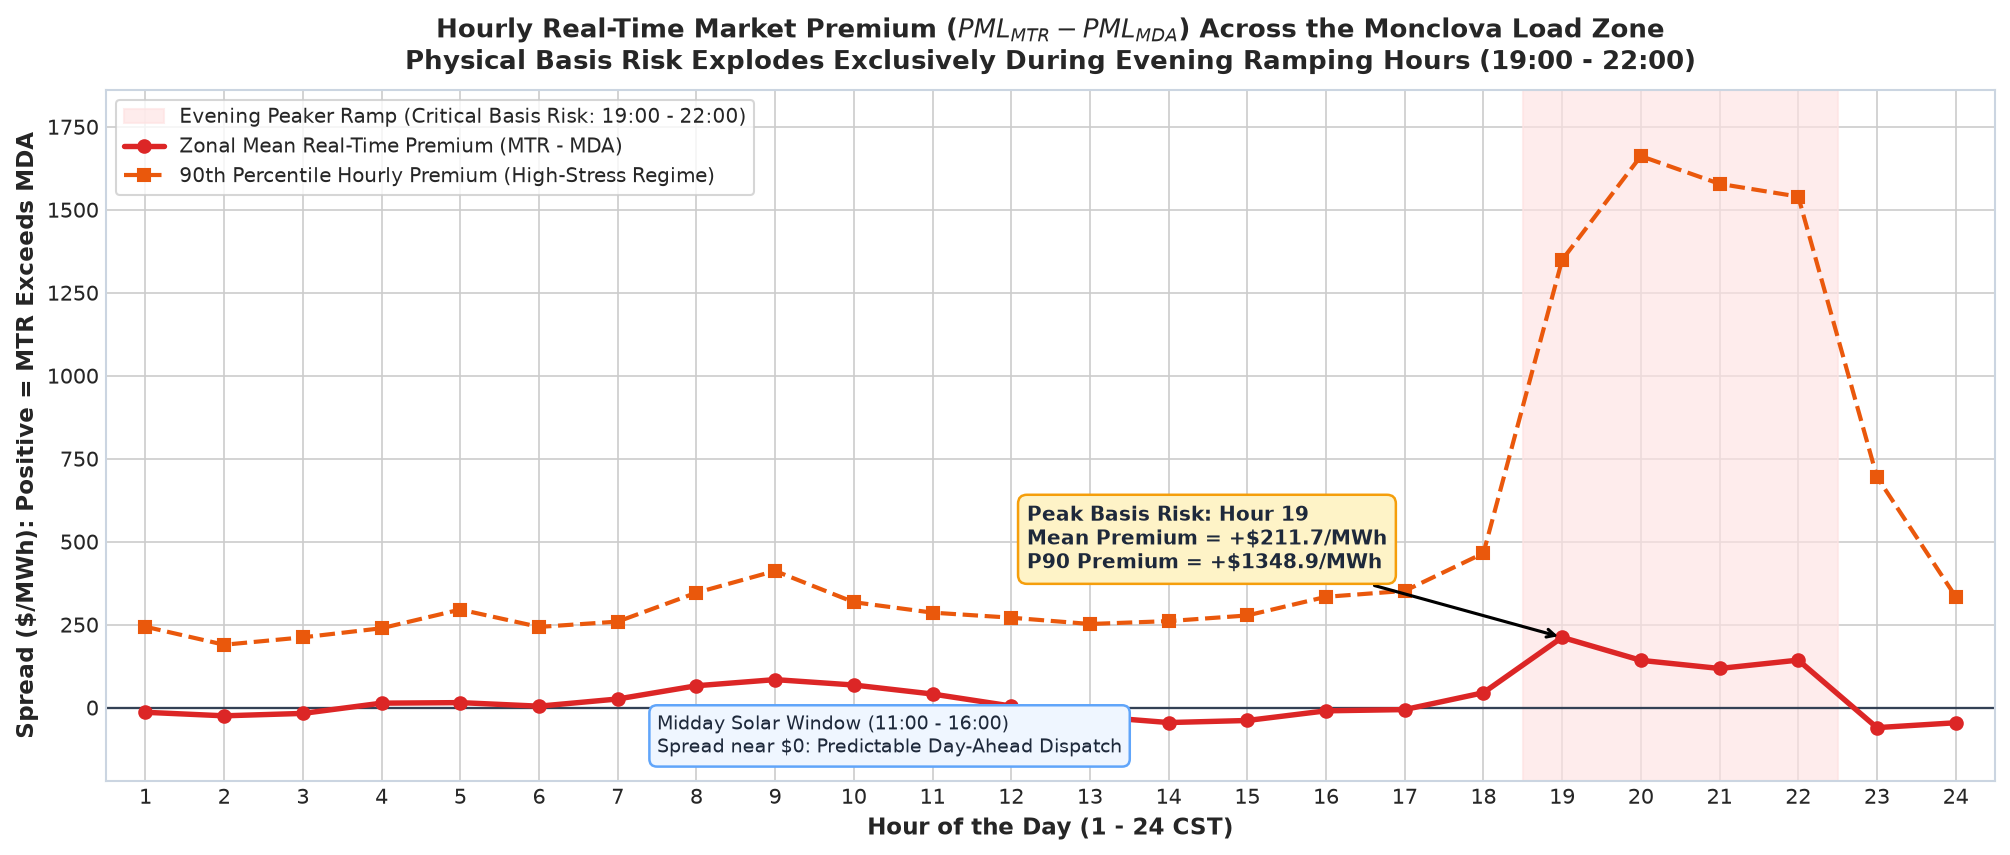

Slide 2 Verified -> Peak Hour 19: Mean +$211.66/MWh, P90 +$1348.91/MWh


In [2]:
hourly_spread = df.groupby('hora')['pml_spread_mtr_minus_mda'].agg(
    mean='mean',
    p90=lambda s: np.percentile(s, 90),
).reset_index()

peak_hr = int(hourly_spread.loc[hourly_spread['mean'].idxmax(), 'hora'])
peak_mean = float(hourly_spread.loc[hourly_spread['hora'] == peak_hr, 'mean'].values[0])
peak_p90 = float(hourly_spread.loc[hourly_spread['hora'] == peak_hr, 'p90'].values[0])

fig, ax = plt.subplots(figsize=(13.5, 5.8))
ax.axvspan(18.5, 22.5, color='#FEE2E2', alpha=0.65, label='Evening Peaker Ramp (Critical Basis Risk: 19:00 - 22:00)')
ax.axhline(0, color='#334155', lw=1.1)

ax.plot(hourly_spread['hora'], hourly_spread['mean'], 'o-', color='#DC2626', lw=2.6, ms=6,
        label='Zonal Mean Real-Time Premium (MTR - MDA)')
ax.plot(hourly_spread['hora'], hourly_spread['p90'], 's--', color='#EA580C', lw=2.0, ms=5.5,
        label='90th Percentile Hourly Premium (High-Stress Regime)')

ax.annotate(
    f"Peak Basis Risk: Hour {peak_hr}\nMean Premium = +${peak_mean:.1f}/MWh\nP90 Premium = +${peak_p90:.1f}/MWh",
    xy=(peak_hr, peak_mean), xytext=(12.2, 420),
    bbox=dict(boxstyle='round,pad=0.45', facecolor='#FEF3C7', edgecolor='#F59E0B', lw=1.2),
    arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
    fontsize=9.5, fontweight='bold', color='#1E293B'
)
ax.annotate(
    "Midday Solar Window (11:00 - 16:00)\nSpread near $0: Predictable Day-Ahead Dispatch",
    xy=(13.5, float(hourly_spread.loc[hourly_spread['hora'] == 14, 'mean'].values[0])),
    xytext=(7.5, -135),
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#EFF6FF', edgecolor='#60A5FA', lw=1.2),
    arrowprops=dict(arrowstyle='->', color='black', lw=1.4),
    fontsize=9.2, color='#1E293B'
)

ax.set_xticks(range(1, 25))
ax.set_xlim(0.5, 24.5)
ax.set_ylim(-220, hourly_spread['p90'].max() * 1.12)
ax.set_xlabel('Hour of the Day (1 - 24 CST)', fontsize=11, fontweight='bold')
ax.set_ylabel('Spread ($/MWh): Positive = MTR Exceeds MDA', fontsize=11, fontweight='bold')
ax.set_title('Hourly Real-Time Market Premium ($PML_{MTR} - PML_{MDA}$) Across the Monclova Load Zone\n'
             'Physical Basis Risk Explodes Exclusively During Evening Ramping Hours (19:00 - 22:00)',
             fontsize=12.5, fontweight='bold', pad=10)
ax.legend(loc='upper left', fontsize=9.5, frameon=True, facecolor='white')

plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_02_mtr_basis_premium.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Slide 2 Verified -> Peak Hour {peak_hr}: Mean +${peak_mean:.2f}/MWh, P90 +${peak_p90:.2f}/MWh")


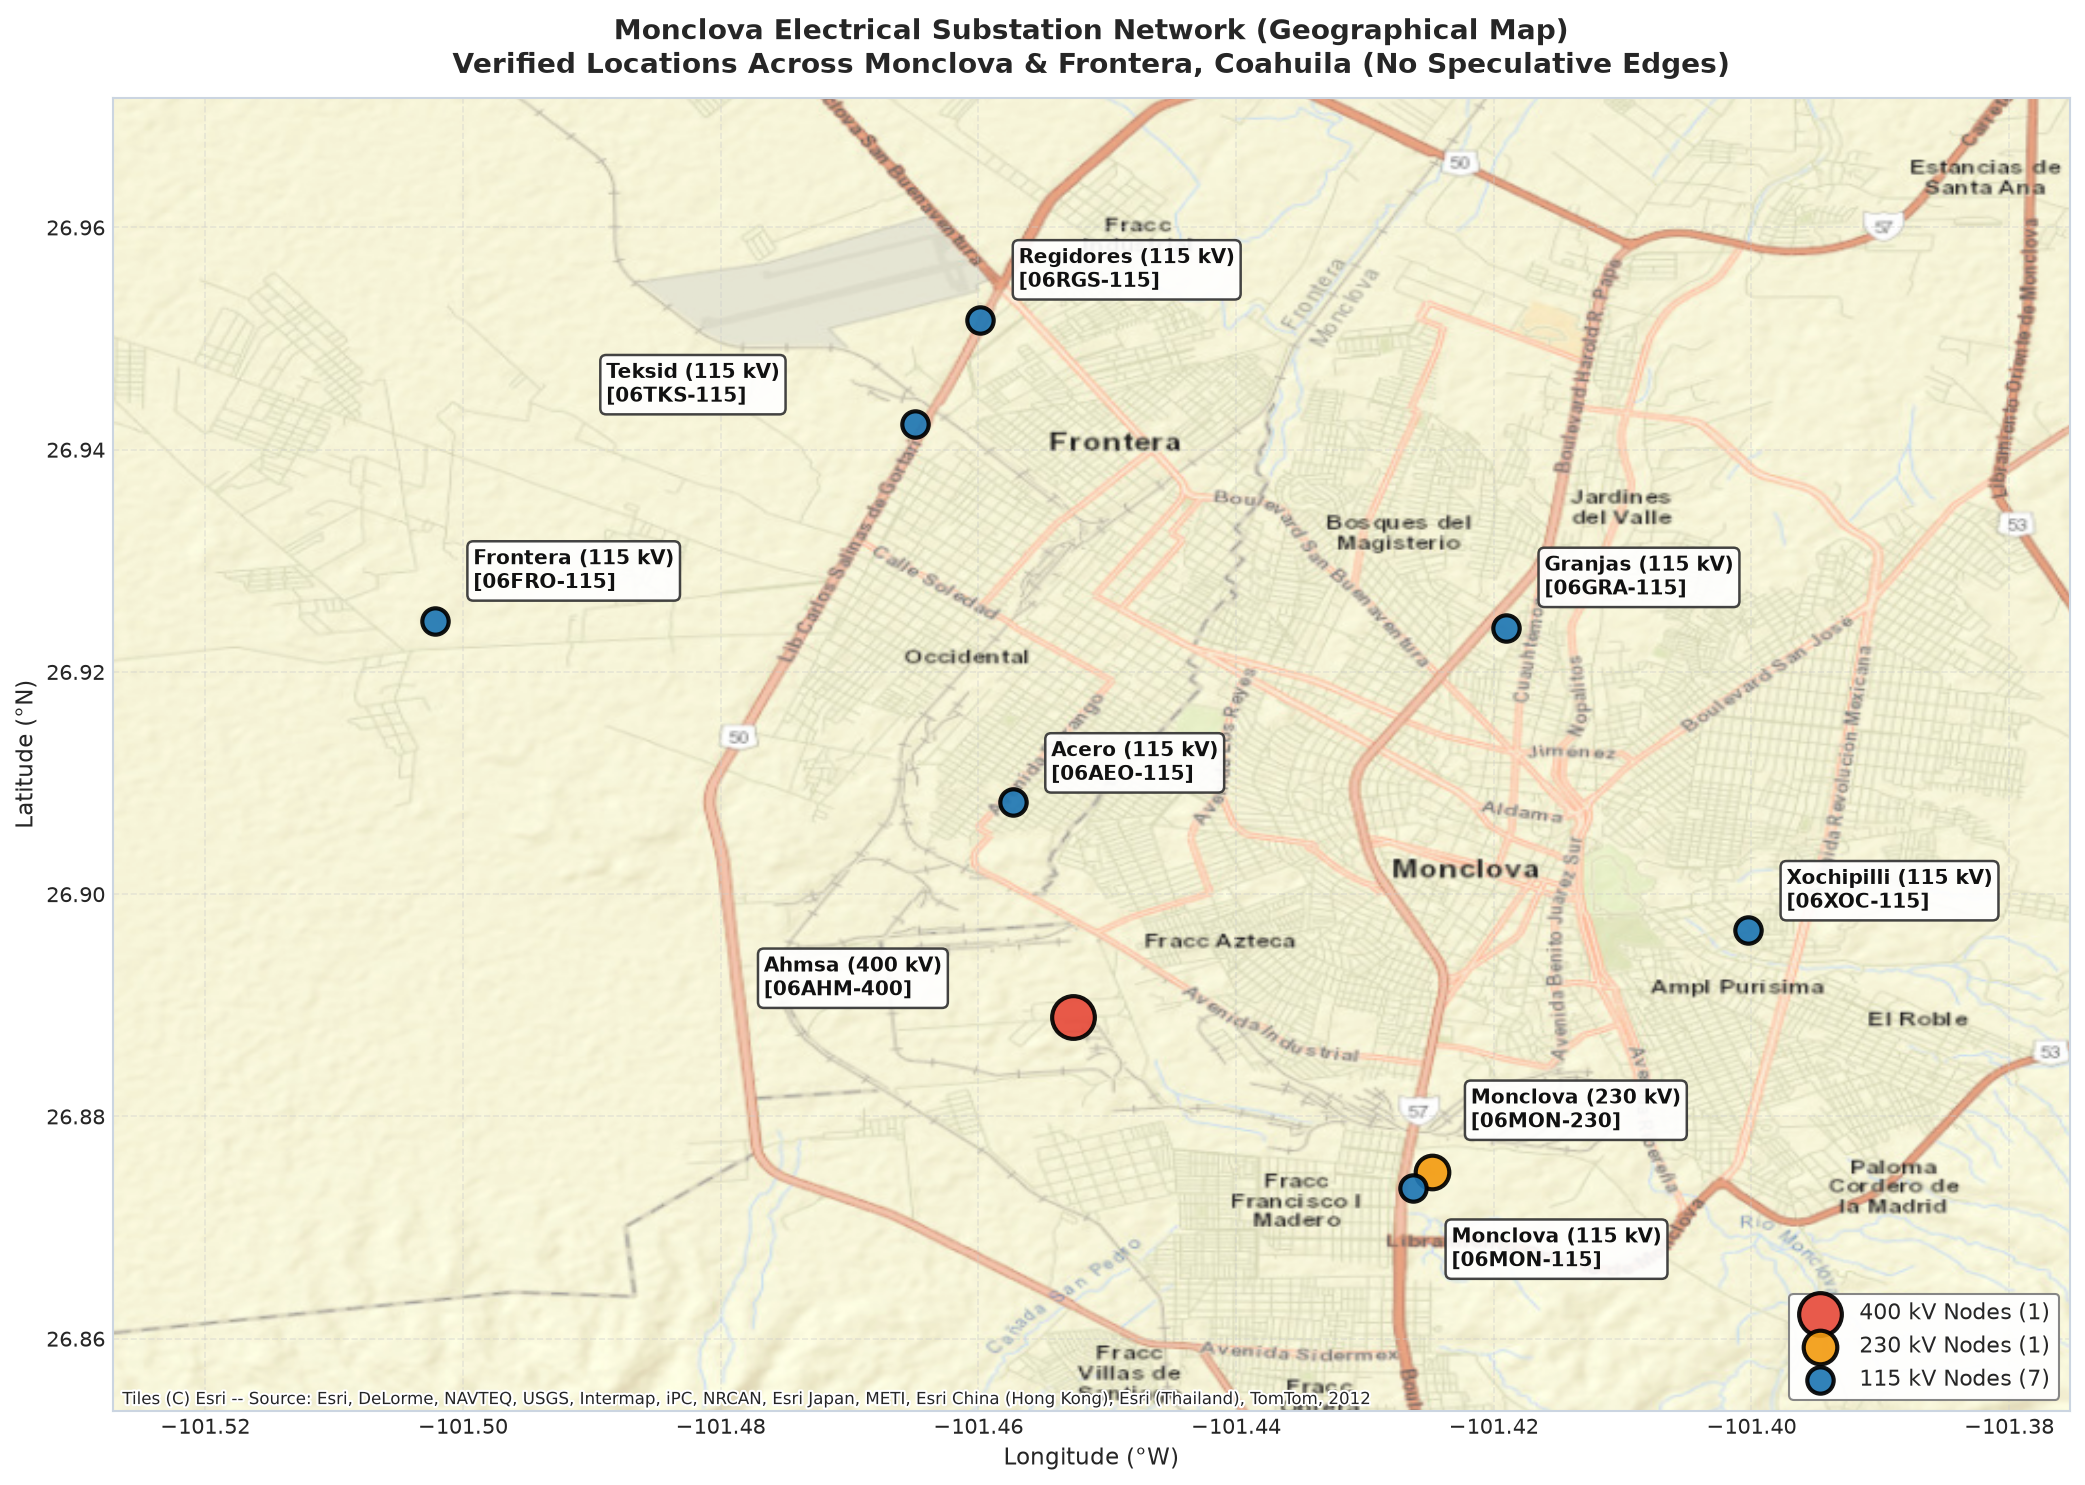

Slide 3 Verified -> Mapped 9 Monclova substations onto Esri WorldStreetMap


In [3]:
NODAL_SPECS = {
    '06AEO-115': {'name': 'Acero', 'voltage_kv': 115.0, 'municipality': 'Monclova / Frontera', 'lat': 26.908287, 'lon': -101.457346},
    '06AHM-400': {'name': 'Ahmsa', 'voltage_kv': 400.0, 'municipality': 'Monclova', 'lat': 26.888905, 'lon': -101.452644},
    '06FRO-115': {'name': 'Frontera', 'voltage_kv': 115.0, 'municipality': 'Frontera', 'lat': 26.924558, 'lon': -101.502196},
    '06GRA-115': {'name': 'Granjas', 'voltage_kv': 115.0, 'municipality': 'Monclova', 'lat': 26.923979, 'lon': -101.419065},
    '06MON-115': {'name': 'Monclova', 'voltage_kv': 115.0, 'municipality': 'Monclova', 'lat': 26.873526, 'lon': -101.426278},
    '06MON-230': {'name': 'Monclova', 'voltage_kv': 230.0, 'municipality': 'Monclova', 'lat': 26.873526, 'lon': -101.426278},
    '06RGS-115': {'name': 'Regidores', 'voltage_kv': 115.0, 'municipality': 'Frontera', 'lat': 26.951658, 'lon': -101.459869},
    '06TKS-115': {'name': 'Teksid', 'voltage_kv': 115.0, 'municipality': 'Frontera', 'lat': 26.942323, 'lon': -101.464880},
    '06XOC-115': {'name': 'Xochipilli', 'voltage_kv': 115.0, 'municipality': 'Monclova', 'lat': 26.896784, 'lon': -101.400280},
}

nodes_df = pd.DataFrame.from_dict(NODAL_SPECS, orient='index').reset_index().rename(columns={'index': 'clv_nodo'})
fig, ax = plt.subplots(figsize=(14, 10))

voltage_colors = {400.0: '#e74c3c', 230.0: '#f39c12', 115.0: '#1f77b4'}
voltage_sizes = {400.0: 420, 230.0: 260, 115.0: 160}

# Visual offset for co-located 230/115 kV switchyards inside CFE Monclova
plot_df = nodes_df.copy()
mask_230 = plot_df['clv_nodo'] == '06MON-230'
plot_df.loc[mask_230, 'lat'] += 0.0015
plot_df.loc[mask_230, 'lon'] += 0.0015

for v_kv in [400.0, 230.0, 115.0]:
    sub = plot_df[plot_df['voltage_kv'] == v_kv]
    ax.scatter(
        sub['lon'], sub['lat'], s=voltage_sizes[v_kv], c=voltage_colors[v_kv],
        edgecolors='black', linewidths=2.0, alpha=0.92, label=f'{int(v_kv)} kV Nodes ({len(sub)})', zorder=5
    )

offsets = {
    '06RGS-115': (0.003, 0.003),
    '06TKS-115': (-0.024, 0.002),
    '06FRO-115': (0.003, 0.003),
    '06GRA-115': (0.003, 0.003),
    '06AEO-115': (0.003, 0.002),
    '06XOC-115': (0.003, 0.002),
    '06AHM-400': (-0.024, 0.002),
    '06MON-230': (0.003, 0.004),
    '06MON-115': (0.003, -0.007),
}

for _, row in plot_df.iterrows():
    code = row['clv_nodo']
    dx, dy = offsets.get(code, (0.002, 0.003))
    label = f"{row['name']} ({int(row['voltage_kv'])} kV)\n[{code}]"
    ax.annotate(
        label, (row['lon'] + dx, row['lat'] + dy), fontsize=9.5, fontweight='bold', color='#111111',
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#333333', alpha=0.92, lw=1.2), zorder=6
    )

pad_lon, pad_lat = 0.025, 0.02
ax.set_xlim(nodes_df['lon'].min() - pad_lon, nodes_df['lon'].max() + pad_lon)
ax.set_ylim(nodes_df['lat'].min() - pad_lat, nodes_df['lat'].max() + pad_lat)

try:
    cx.add_basemap(ax, crs='EPSG:4326', source=cx.providers.Esri.WorldStreetMap, alpha=0.9)
except Exception as exc:
    print(f"Basemap tile fallback notice: {exc}")

ax.set_title('Monclova Electrical Substation Network (Geographical Map)\n'
             'Verified Locations Across Monclova & Frontera, Coahuila (No Speculative Edges)',
             fontsize=13.5, fontweight='bold', pad=12)
ax.set_xlabel('Longitude (°W)', fontsize=11)
ax.set_ylabel('Latitude (°N)', fontsize=11)
ax.legend(loc='lower right', frameon=True, fontsize=10.5, facecolor='white', framealpha=0.95, edgecolor='gray')
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_03_spatial_grid_topology.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"Slide 3 Verified -> Mapped {len(nodes_df)} Monclova substations onto Esri WorldStreetMap")


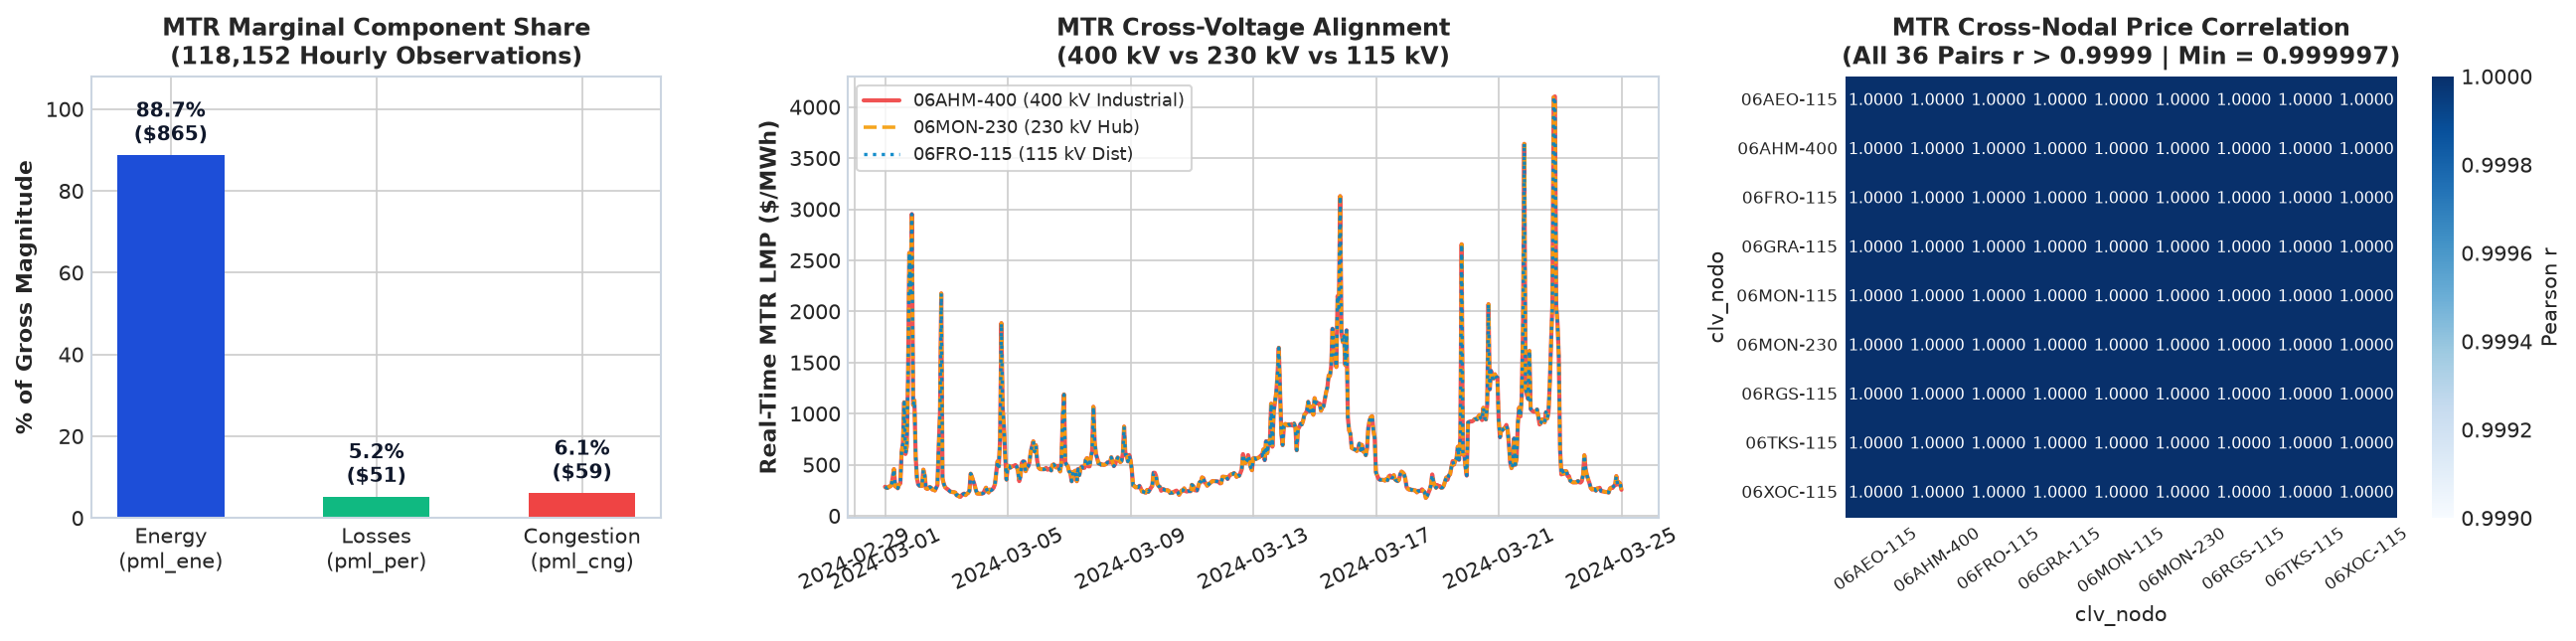

Slide 5 MTR Verified -> Energy: 88.7% ($864.84) | Losses: 5.2% ($50.76) | Congestion: 6.1% ($59.10)
Min cross-nodal Pearson r = 0.999997 | Median total MTR intra-zonal spread = $2.52/MWh | Median congestion spread = $0.01/MWh


In [4]:
# 1. MTR Gross Magnitude Component Shares
ene_abs = float(df['pml_ene_mtr'].abs().mean())
per_abs = float(df['pml_per_mtr'].abs().mean())
cng_abs = float(df['pml_cng_mtr'].abs().mean())
tot_abs = ene_abs + per_abs + cng_abs
shares = [ene_abs / tot_abs * 100.0, per_abs / tot_abs * 100.0, cng_abs / tot_abs * 100.0]

# 2. Cross-nodal correlation & congestion delta on MTR
piv_mtr = df.pivot(index='timestamp', columns='clv_nodo', values='pml_mtr')
corr_mat = piv_mtr.corr()
min_r = float(corr_mat.values[np.triu_indices(9, 1)].min())

piv_cng = df.pivot(index='timestamp', columns='clv_nodo', values='pml_cng_mtr')
median_cng_spread = float((piv_cng.max(axis=1) - piv_cng.min(axis=1)).median())
median_mtr_spread = float((piv_mtr.max(axis=1) - piv_mtr.min(axis=1)).median())

fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.4), gridspec_kw={'width_ratios': [0.95, 1.35, 1.15]})

# Panel 1: Gross Component Share (MTR)
bars = axes[0].bar(
    ['Energy\n(pml_ene)', 'Losses\n(pml_per)', 'Congestion\n(pml_cng)'],
    shares, color=['#1D4ED8', '#10B981', '#EF4444'], width=0.52, edgecolor='none'
)
for b, val, mx in zip(bars, shares, [ene_abs, per_abs, cng_abs]):
    axes[0].text(b.get_x() + b.get_width()/2, val + 2.0, f"{val:.1f}%\n(${mx:.0f})",
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#0F172A')
axes[0].set_ylim(0, 108)
axes[0].set_ylabel('% of Gross Magnitude', fontsize=10.5, fontweight='bold')
axes[0].set_title('MTR Marginal Component Share\n(118,152 Hourly Observations)', fontsize=11.5, fontweight='bold')

# Panel 2: Cross-Voltage Alignment (MTR)
win_mask = (df['timestamp'] >= '2024-03-01') & (df['timestamp'] <= '2024-03-25')
for node, col, ls, lw, lbl in [
    ('06AHM-400', '#EF4444', '-', 2.0, '06AHM-400 (400 kV Industrial)'),
    ('06MON-230', '#F59E0B', '--', 1.7, '06MON-230 (230 kV Hub)'),
    ('06FRO-115', '#0284C7', ':', 1.6, '06FRO-115 (115 kV Dist)'),
]:
    sub = df[win_mask & (df['clv_nodo'] == node)]
    axes[1].plot(sub['timestamp'], sub['pml_mtr'], color=col, ls=ls, lw=lw, label=lbl, alpha=0.92)
axes[1].set_title('MTR Cross-Voltage Alignment\n(400 kV vs 230 kV vs 115 kV)', fontsize=11.5, fontweight='bold')
axes[1].set_ylabel('Real-Time MTR LMP ($/MWh)', fontsize=10.5, fontweight='bold')
axes[1].tick_params(axis='x', rotation=25)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
axes[1].legend(loc='upper left', fontsize=8.5, frameon=True, facecolor='white')

# Panel 3: Correlation Heatmap (MTR)
sns.heatmap(corr_mat, annot=True, fmt='.4f', cmap='Blues', vmin=0.9990, vmax=1.0000,
            cbar_kws={'label': 'Pearson r'}, annot_kws={'size': 7.5}, ax=axes[2])
axes[2].set_title(f'MTR Cross-Nodal Price Correlation\n(All 36 Pairs r > 0.9999 | Min = {min_r:.6f})', fontsize=11.5, fontweight='bold')
axes[2].tick_params(axis='x', rotation=35, labelsize=8)
axes[2].tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_05_mtr_physics_and_coherence.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"Slide 5 MTR Verified -> Energy: {shares[0]:.1f}% (${ene_abs:.2f}) | Losses: {shares[1]:.1f}% (${per_abs:.2f}) | Congestion: {shares[2]:.1f}% (${cng_abs:.2f})")
print(f"Min cross-nodal Pearson r = {min_r:.6f} | Median total MTR intra-zonal spread = ${median_mtr_spread:.2f}/MWh | Median congestion spread = ${median_cng_spread:.2f}/MWh")


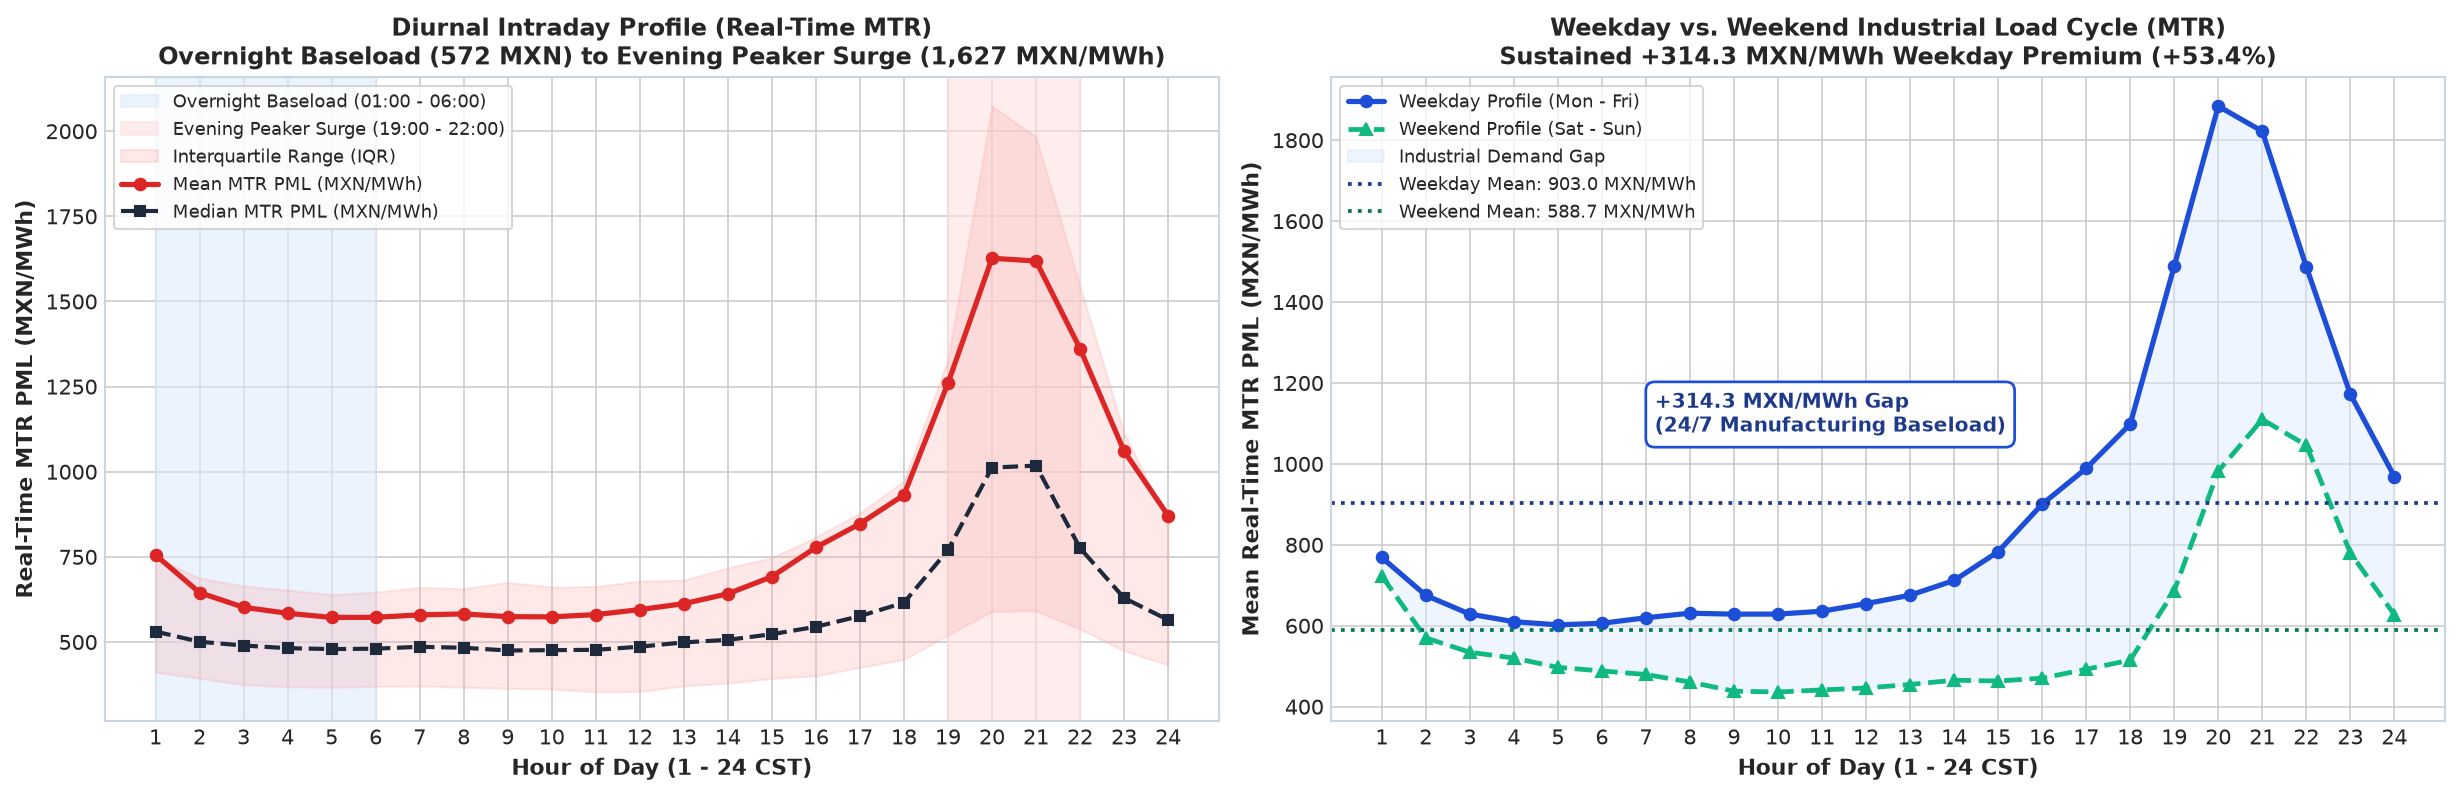

Slide 6 MTR Verified -> Diurnal min: HE 5 ($572.2), max: HE 20 ($1627.0)
Weekday Mean: $903.0 vs Weekend Mean: $588.7 (+$314.3 MXN/MWh gap)


In [5]:
diurnal_mtr = df.groupby('hora')['pml_mtr'].agg(
    mean='mean',
    median='median',
    q25=lambda s: np.percentile(s, 25),
    q75=lambda s: np.percentile(s, 75),
).reset_index()

wk_prof = df.groupby(['is_weekend', 'hora'])['pml_mtr'].mean().unstack(0)
wkday_mean = float(df.loc[df['is_weekend'] == 0, 'pml_mtr'].mean())
wkend_mean = float(df.loc[df['is_weekend'] == 1, 'pml_mtr'].mean())
wk_gap = wkday_mean - wkend_mean

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 5.4))

# Left: Diurnal Profile (MTR)
ax1.axvspan(1, 6, color='#DBEAFE', alpha=0.55, label='Overnight Baseload (01:00 - 06:00)')
ax1.axvspan(19, 22, color='#FEE2E2', alpha=0.60, label='Evening Peaker Surge (19:00 - 22:00)')
ax1.fill_between(diurnal_mtr['hora'], diurnal_mtr['q25'], diurnal_mtr['q75'],
                 color='#FCA5A5', alpha=0.25, label='Interquartile Range (IQR)')
ax1.plot(diurnal_mtr['hora'], diurnal_mtr['mean'], 'o-', color='#DC2626', lw=2.5, ms=5.5, label='Mean MTR PML (MXN/MWh)')
ax1.plot(diurnal_mtr['hora'], diurnal_mtr['median'], 's--', color='#1E293B', lw=2.0, ms=4.5, label='Median MTR PML (MXN/MWh)')
ax1.set_xticks(range(1, 25))
ax1.set_xlabel('Hour of Day (1 - 24 CST)', fontsize=10.5, fontweight='bold')
ax1.set_ylabel('Real-Time MTR PML (MXN/MWh)', fontsize=10.5, fontweight='bold')
ax1.set_title('Diurnal Intraday Profile (Real-Time MTR)\n'
              f'Overnight Baseload ({diurnal_mtr.loc[diurnal_mtr["hora"].between(1,6), "mean"].min():.0f} MXN) '
              f'to Evening Peaker Surge ({diurnal_mtr["mean"].max():,.0f} MXN/MWh)',
              fontsize=11.5, fontweight='bold')
ax1.legend(loc='upper left', fontsize=8.8, frameon=True, facecolor='white')

# Right: Weekday vs Weekend (MTR)
ax2.plot(wk_prof.index, wk_prof[0], 'o-', color='#1D4ED8', lw=2.5, ms=5.5, label='Weekday Profile (Mon - Fri)')
ax2.plot(wk_prof.index, wk_prof[1], '^--', color='#10B981', lw=2.3, ms=5.5, label='Weekend Profile (Sat - Sun)')
ax2.fill_between(wk_prof.index, wk_prof[1], wk_prof[0], color='#DBEAFE', alpha=0.45, label='Industrial Demand Gap')
ax2.axhline(wkday_mean, color='#1E3A8A', ls=':', lw=1.8, label=f'Weekday Mean: {wkday_mean:.1f} MXN/MWh')
ax2.axhline(wkend_mean, color='#047857', ls=':', lw=1.8, label=f'Weekend Mean: {wkend_mean:.1f} MXN/MWh')

ax2.annotate(
    f"+{wk_gap:.1f} MXN/MWh Gap\n(24/7 Manufacturing Baseload)",
    xy=(14, (wkday_mean + wkend_mean) / 2), xytext=(7.2, 1080),
    bbox=dict(boxstyle='round,pad=0.45', facecolor='white', edgecolor='#1D4ED8', lw=1.3),
    fontsize=9.5, fontweight='bold', color='#1E3A8A'
)
ax2.set_xticks(range(1, 25))
ax2.set_xlabel('Hour of Day (1 - 24 CST)', fontsize=10.5, fontweight='bold')
ax2.set_ylabel('Mean Real-Time MTR PML (MXN/MWh)', fontsize=10.5, fontweight='bold')
ax2.set_title(f'Weekday vs. Weekend Industrial Load Cycle (MTR)\n'
              f'Sustained +{wk_gap:.1f} MXN/MWh Weekday Premium (+{wk_gap/wkend_mean*100:.1f}%)',
              fontsize=11.5, fontweight='bold')
ax2.legend(loc='upper left', fontsize=8.8, frameon=True, facecolor='white')

plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_06_mtr_temporal_dynamics.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"Slide 6 MTR Verified -> Diurnal min: HE {int(diurnal_mtr.loc[diurnal_mtr['mean'].idxmin(), 'hora'])} (${diurnal_mtr['mean'].min():.1f}), "
      f"max: HE {int(diurnal_mtr.loc[diurnal_mtr['mean'].idxmax(), 'hora'])} (${diurnal_mtr['mean'].max():.1f})")
print(f"Weekday Mean: ${wkday_mean:.1f} vs Weekend Mean: ${wkend_mean:.1f} (+${wk_gap:.1f} MXN/MWh gap)")


In [6]:
df['hour_sin'] = np.sin(2 * np.pi * df['hora'] / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['hora'] / 24.0)
df['dow_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7.0)
df['dow_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7.0)
df['voltage_norm'] = df['tension_kv'] / 400.0
df['is_400kv'] = (df['tension_kv'] == 400.0).astype(int)

g_mtr = df.groupby('clv_nodo')['pml_mtr']
for l in [1, 2, 24, 168]:
    df[f'mtr_lag_{l}'] = g_mtr.shift(l)
df['mtr_roll_mean_6h'] = g_mtr.transform(lambda s: s.shift(1).rolling(6).mean())
df['mtr_roll_std_24h'] = g_mtr.transform(lambda s: s.shift(1).rolling(24).std())
df['mtr_roll_max_24h'] = g_mtr.transform(lambda s: s.shift(1).rolling(24).max())

FEATS = [
    'mtr_lag_1', 'mtr_lag_2', 'mtr_lag_24', 'mtr_lag_168',
    'mtr_roll_mean_6h', 'mtr_roll_std_24h', 'mtr_roll_max_24h',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend',
    'voltage_norm', 'is_400kv',
]
FEATS_NODE = [f for f in FEATS if f not in ['voltage_norm', 'is_400kv']]

train_df = df[(df['timestamp'] >= '2024-01-09') & (df['timestamp'] < '2025-01-01')].copy().reset_index(drop=True)
test_df = df[df['timestamp'] >= '2025-01-01'].copy().reset_index(drop=True)

X_tr, y_tr = train_df[FEATS], train_df['pml_mtr'].values
X_te, y_te = test_df[FEATS], test_df['pml_mtr'].values

def score_row(name, y_pred):
    abs_err = np.abs(y_te - y_pred)
    return {
        'Model': name,
        'MAE ($)': mean_absolute_error(y_te, y_pred),
        'RMSE ($)': root_mean_squared_error(y_te, y_pred),
        'WAPE (%)': abs_err.sum() / np.abs(y_te).sum() * 100.0,
        'R2': r2_score(y_te, y_pred),
        'Prec <=$50 (%)': float((abs_err <= 50.0).mean() * 100.0),
        'Prec <=$100 (%)': float((abs_err <= 100.0).mean() * 100.0),
    }

# 1. SARIMA(1,0,1)(1,0,1,24) per node -> concatenated strictly across N=39,096 test node-hours
t0 = time.time()
pred_sarima_s = pd.Series(index=test_df.index, dtype=float)
for node, grp in df.groupby('clv_nodo'):
    grp = grp.sort_values('timestamp')
    tr_y = grp[grp['timestamp'] < '2025-01-01']['pml_mtr'].values
    mod = SARIMAX(tr_y, order=(1, 0, 1), seasonal_order=(1, 0, 1, 24), trend='c',
                  enforce_stationarity=False, enforce_invertibility=False)
    res = mod.fit(disp=False, maxiter=40)
    res_full = SARIMAX(grp['pml_mtr'].values, order=(1, 0, 1), seasonal_order=(1, 0, 1, 24), trend='c',
                       enforce_stationarity=False, enforce_invertibility=False).filter(res.params)
    pred_sarima_s.loc[test_df.index[test_df['clv_nodo'] == node]] = res_full.fittedvalues[len(tr_y):]
pred_sarima = pred_sarima_s.values
print(f"9-Node SARIMA runtime: {time.time() - t0:.1f}s")

# 2. Ridge Regression (L2)
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)
ridge = Ridge(alpha=10.0).fit(X_tr_s, y_tr)
pred_ridge = ridge.predict(X_te_s)

# Reference Linear L1 check (SGD L1+L2 & Huber) for appendix comparison
sgd_l1 = SGDRegressor(loss='epsilon_insensitive', epsilon=0.0, penalty='l2', alpha=1e-4,
                      learning_rate='adaptive', eta0=0.5, max_iter=2000, tol=1e-4, random_state=42).fit(X_tr_s, y_tr)
pred_sgd_l1 = sgd_l1.predict(X_te_s)
huber = HuberRegressor(max_iter=500).fit(X_tr_s, y_tr)
pred_huber = huber.predict(X_te_s)

# 3. HistGBDT (L1 MAE Loss) - Unified Champion
hgb_l1 = HistGradientBoostingRegressor(
    loss='absolute_error', max_iter=150, learning_rate=0.08, max_leaf_nodes=31, random_state=42
).fit(X_tr, y_tr)
pred_hgb_l1 = hgb_l1.predict(X_te)

# Reference HistGBDT (L2) & 9 Separate Node Models Proof
hgb_l2 = HistGradientBoostingRegressor(
    loss='squared_error', max_iter=150, learning_rate=0.08, max_leaf_nodes=31, random_state=42
).fit(X_tr, y_tr)
pred_hgb_l2 = hgb_l2.predict(X_te)

preds_sep = pd.Series(index=test_df.index, dtype=float)
for node in df['clv_nodo'].unique():
    tr_m = train_df['clv_nodo'] == node
    te_m = test_df['clv_nodo'] == node
    m_sep = HistGradientBoostingRegressor(
        loss='absolute_error', max_iter=150, learning_rate=0.08, max_leaf_nodes=31, random_state=42
    ).fit(train_df.loc[tr_m, FEATS_NODE], train_df.loc[tr_m, 'pml_mtr'])
    preds_sep.loc[te_m] = m_sep.predict(test_df.loc[te_m, FEATS_NODE])

leaderboard = pd.DataFrame([
    score_row('Ref: Naive Persistence (MTR_t-1)', test_df['mtr_lag_1'].values),
    score_row('SARIMA (1,0,1)x(1,0,1,24)', pred_sarima),
    score_row('Ridge Regression (L2)', pred_ridge),
    score_row('HistGBDT (L1 MAE Loss) [Unified]', pred_hgb_l1),
    score_row('Ref: HistGBDT (L1) [9 Separate Models]', preds_sep.values),
    score_row('Ref: HistGBDT (L2 MSE Loss)', pred_hgb_l2),
    score_row('Ref: Linear L1+L2 (SGD)', pred_sgd_l1),
    score_row('Ref: Huber Robust Linear', pred_huber),
])
print("=== SLIDE 5 & SLIDE 7 VERIFIED MTR LEADERBOARD (2025 TEST, N=39,096) ===")
display(leaderboard.round(3))


9-Node SARIMA runtime: 65.3s


=== SLIDE 5 & SLIDE 7 VERIFIED MTR LEADERBOARD (2025 TEST, N=39,096) ===


,Model,MAE ($),RMSE ($),WAPE (%),R2,Prec <=$50 (%),Prec <=$100 (%)
0,Ref: Naive Persistence (MTR_t-1),103.050,372.490,13.575,0.477,70.445,82.794
1,"SARIMA (1,0,1)x(1,0,1,24)",134.220,342.068,17.681,0.559,25.576,68.319
2,Ridge Regression (L2),142.647,338.703,18.791,0.568,30.059,57.392
3,HistGBDT (L1 MAE Loss) [Unified],101.100,319.430,13.318,0.615,62.326,79.929
4,Ref: HistGBDT (L1) [9 Separate Models],101.044,316.991,13.311,0.621,61.728,79.520
5,Ref: HistGBDT (L2 MSE Loss),121.122,337.814,15.955,0.570,56.893,75.343
6,Ref: Linear L1+L2 (SGD),109.355,344.230,14.405,0.553,61.456,79.650
7,Ref: Huber Robust Linear,100.000,358.636,13.173,0.515,70.989,83.763


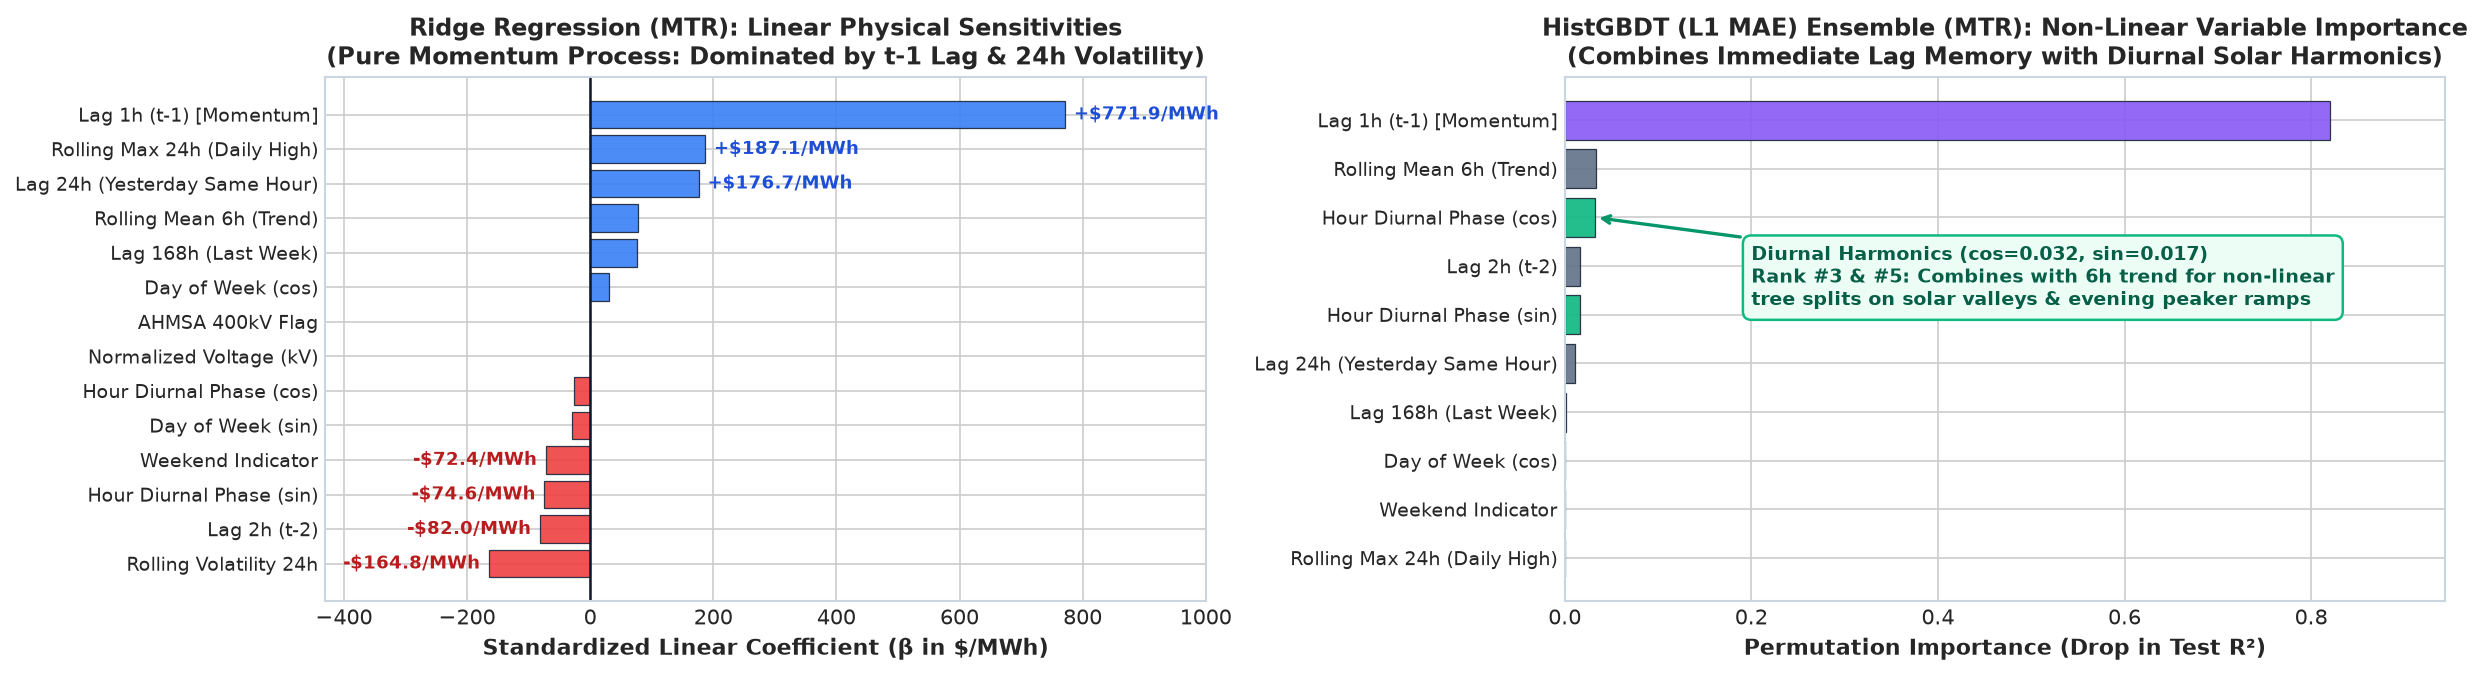

Ridge L1 weight share on lag_1: 43.6% | L2 energy share on lag_1: 82.6% | Total AR/rolling share: 86.7%
Top 6 Ridge Coefs (MTR):
mtr_lag_1           771.92
mtr_roll_max_24h    187.09
mtr_lag_24          176.69
mtr_roll_std_24h   -164.76
mtr_lag_2           -81.97
mtr_roll_mean_6h     77.16
dtype: float64

Top 6 HistGBDT (L1) Permutation Importances (MTR):
mtr_lag_1           0.8204
mtr_roll_mean_6h    0.0337
hour_cos            0.0324
mtr_lag_2           0.0167
hour_sin            0.0166
mtr_lag_24          0.0106
dtype: float64


In [7]:
# Friendly readable names matching Slide 8 visual vocabulary
FEAT_LABELS = {
    'mtr_lag_1': 'Lag 1h (t-1) [Momentum]',
    'mtr_lag_2': 'Lag 2h (t-2)',
    'mtr_lag_24': 'Lag 24h (Yesterday Same Hour)',
    'mtr_lag_168': 'Lag 168h (Last Week)',
    'mtr_roll_mean_6h': 'Rolling Mean 6h (Trend)',
    'mtr_roll_std_24h': 'Rolling Volatility 24h',
    'mtr_roll_max_24h': 'Rolling Max 24h (Daily High)',
    'hour_sin': 'Hour Diurnal Phase (sin)',
    'hour_cos': 'Hour Diurnal Phase (cos)',
    'dow_sin': 'Day of Week (sin)',
    'dow_cos': 'Day of Week (cos)',
    'is_weekend': 'Weekend Indicator',
    'voltage_norm': 'Normalized Voltage (kV)',
    'is_400kv': 'AHMSA 400kV Flag',
}

ridge_coefs = pd.Series(ridge.coef_, index=[FEAT_LABELS[c] for c in FEATS]).sort_values()

# Permutation Importance for HistGBDT (L1) on full test sample (N=20,000 for speed & stability)
sample_te = test_df.sample(20000, random_state=42)
perm_l1 = permutation_importance(
    hgb_l1, sample_te[FEATS], sample_te['pml_mtr'].values, n_repeats=5, random_state=42, scoring='r2'
)
gbdt_imp = pd.Series(perm_l1.importances_mean, index=[FEAT_LABELS[c] for c in FEATS]).sort_values()
# Keep top 10 cleanest positive/meaningful drivers for right panel
gbdt_top10 = gbdt_imp.tail(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 4.6))

# Left: Ridge Standardized Coefficients (zero text clipping!)
bar_colors = ['#EF4444' if v < 0 else '#3B82F6' for v in ridge_coefs.values]
ax1.axvline(0, color='#0F172A', lw=1.2)
ax1.barh(ridge_coefs.index, ridge_coefs.values, color=bar_colors, edgecolor='#1E293B', linewidth=0.6, alpha=0.92)
for idx_lbl, val in ridge_coefs.items():
    if val >= 80:
        ax1.text(val + 14, idx_lbl, f"+${val:.1f}/MWh", va='center', ha='left', fontsize=8.5, fontweight='bold', color='#1D4ED8')
    elif val <= -70:
        ax1.text(val - 14, idx_lbl, f"-${abs(val):.1f}/MWh", va='center', ha='right', fontsize=8.5, fontweight='bold', color='#B91C1C')
ax1.set_xlim(-430, 1000)
ax1.set_xlabel('Standardized Linear Coefficient (β in $/MWh)', fontsize=10.5, fontweight='bold')
ax1.set_title('Ridge Regression (MTR): Linear Physical Sensitivities\n'
              '(Pure Momentum Process: Dominated by t-1 Lag & 24h Volatility)', fontsize=11.5, fontweight='bold')
ax1.tick_params(axis='y', labelsize=9)

# Right: HistGBDT (L1) Permutation Importance
gbdt_cols = ['#10B981' if 'Diurnal Phase' in k else ('#8B5CF6' if 'Lag 1h' in k else '#64748B') for k in gbdt_top10.index]
ax2.barh(gbdt_top10.index, gbdt_top10.values, color=gbdt_cols, edgecolor='#1E293B', linewidth=0.6, alpha=0.92)
gbdt_sorted_desc = gbdt_imp.sort_values(ascending=False)
cos_rank = int(list(gbdt_sorted_desc.index).index('Hour Diurnal Phase (cos)')) + 1
sin_rank = int(list(gbdt_sorted_desc.index).index('Hour Diurnal Phase (sin)')) + 1
cos_val = float(gbdt_top10['Hour Diurnal Phase (cos)'])
sin_val = float(gbdt_top10['Hour Diurnal Phase (sin)'])
ax2.annotate(
    f"Diurnal Harmonics (cos={cos_val:.3f}, sin={sin_val:.3f})\n"
    f"Rank #{cos_rank} & #{sin_rank}: Combines with 6h trend for non-linear\n"
    "tree splits on solar valleys & evening peaker ramps",
    xy=(cos_val, 'Hour Diurnal Phase (cos)'), xytext=(0.20, 5.2),
    bbox=dict(boxstyle='round,pad=0.45', facecolor='#ECFDF5', edgecolor='#10B981', lw=1.2),
    arrowprops=dict(arrowstyle='->', color='#059669', lw=1.6),
    fontsize=9.0, fontweight='bold', color='#065F46'
)
ax2.set_xlim(0, max(gbdt_top10.values) * 1.15)
ax2.set_xlabel('Permutation Importance (Drop in Test R²)', fontsize=10.5, fontweight='bold')
ax2.set_title('HistGBDT (L1 MAE) Ensemble (MTR): Non-Linear Variable Importance\n'
              '(Combines Immediate Lag Memory with Diurnal Solar Harmonics)', fontsize=11.5, fontweight='bold')
ax2.tick_params(axis='y', labelsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_08_mtr_feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()

coef_s = pd.Series(ridge.coef_, index=FEATS)
lag1_abs_share = abs(coef_s['mtr_lag_1']) / coef_s.abs().sum() * 100.0
lag1_l2_share = (coef_s['mtr_lag_1'] ** 2) / (coef_s ** 2).sum() * 100.0
lags_abs_share = coef_s[['mtr_lag_1', 'mtr_lag_2', 'mtr_lag_24', 'mtr_lag_168', 'mtr_roll_mean_6h', 'mtr_roll_std_24h', 'mtr_roll_max_24h']].abs().sum() / coef_s.abs().sum() * 100.0
print(f"Ridge L1 weight share on lag_1: {lag1_abs_share:.1f}% | L2 energy share on lag_1: {lag1_l2_share:.1f}% | Total AR/rolling share: {lags_abs_share:.1f}%")
print("Top 6 Ridge Coefs (MTR):")
print(coef_s.sort_values(key=abs, ascending=False).head(6).round(2))
print("\nTop 6 HistGBDT (L1) Permutation Importances (MTR):")
print(pd.Series(perm_l1.importances_mean, index=FEATS).sort_values(ascending=False).head(6).round(4))


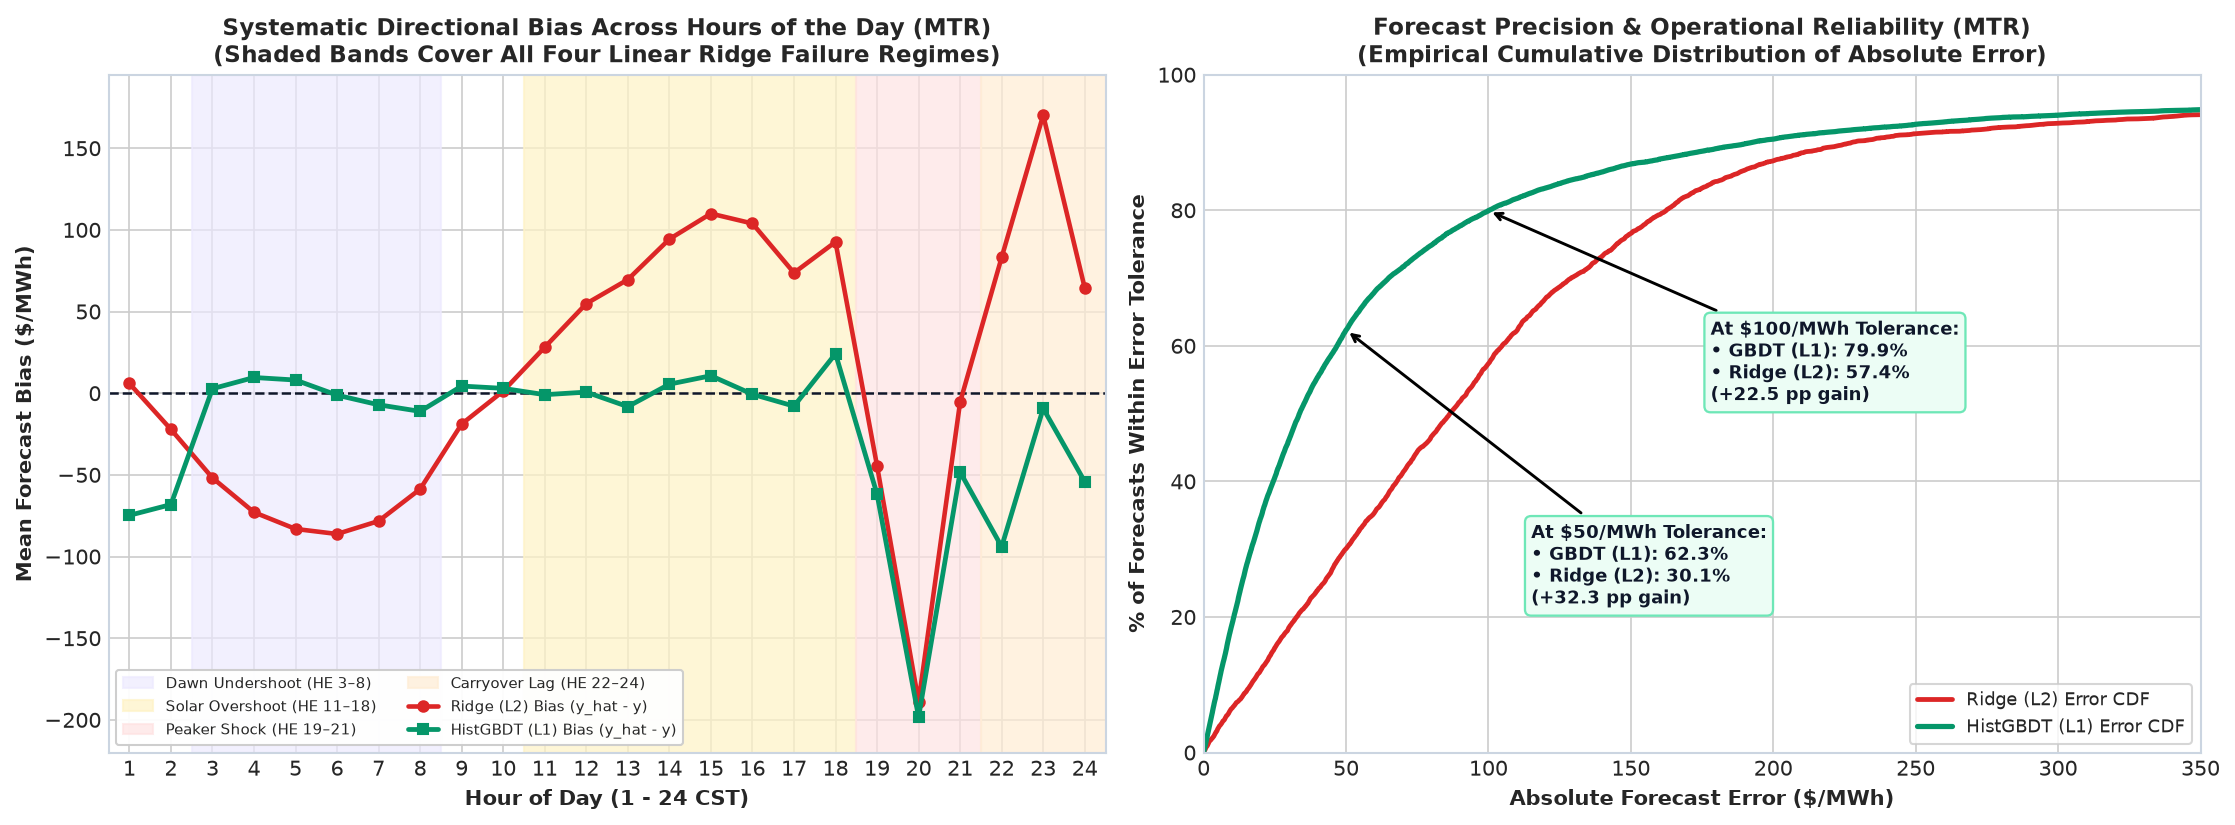

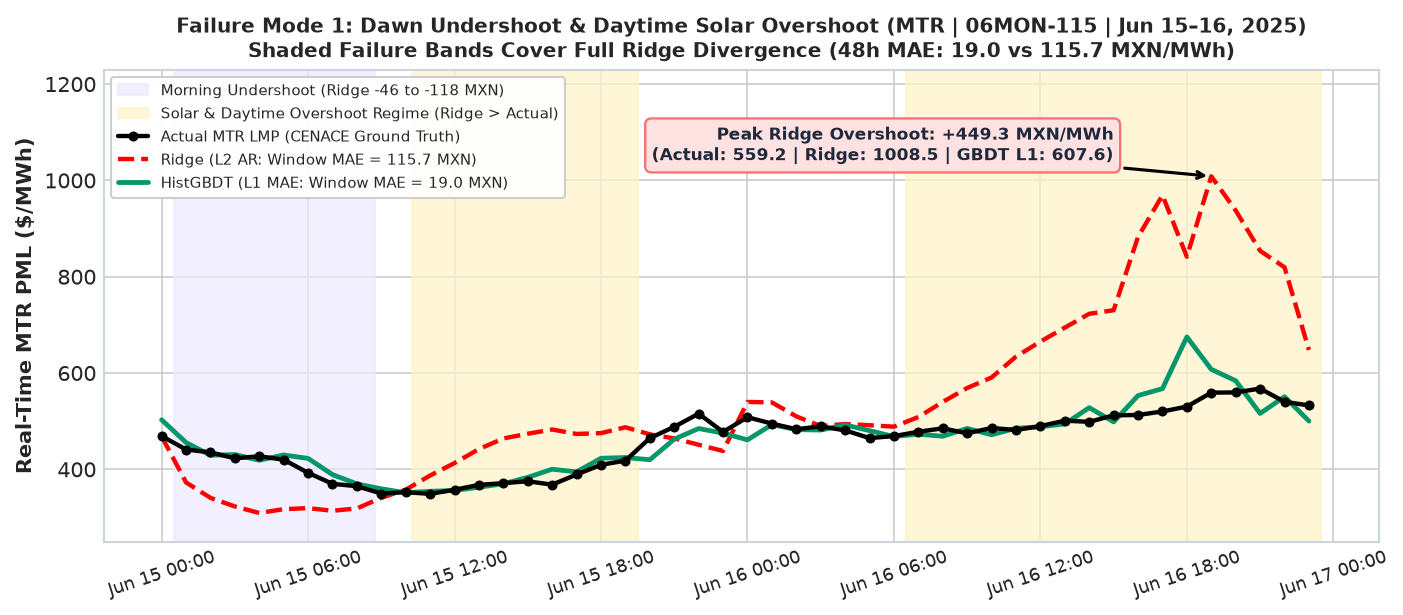

Slide 9 & 10 Bias -> Dawn(3-8h): Ridge=-71.8, GBDT_L1=+0.2
Solar/Daytime(11-18h): Ridge=+78.4, GBDT_L1=+2.9
Peak(19-21h): Ridge=-79.6, GBDT_L1=-102.8 | Post-Peak(22-24h): Ridge=+106.0, GBDT_L1=-52.5
CDF Precision -> <=$50: GBDT_L1 62.3% vs Ridge 30.1% | <=$100: GBDT_L1 79.9% vs Ridge 57.4%
Jan 20-22 Cold Front MAE (MTR) -> Ridge: $128.71 | HistGBDT(L2): $166.87 | HistGBDT(L1): $99.24
Jun 15-16 Window MAE -> Ridge: $115.7 vs GBDT_L1: $19.0 | Peak (2025-06-16 19:00:00): Actual=$559.2, Ridge=$1008.5 (+$449.3), GBDT_L1=$607.6 (+48.4)


In [8]:
test_df['pred_ridge'] = pred_ridge
test_df['pred_hgb_l1'] = pred_hgb_l1
test_df['bias_ridge'] = test_df['pred_ridge'] - test_df['pml_mtr']
test_df['bias_hgb_l1'] = test_df['pred_hgb_l1'] - test_df['pml_mtr']

bias_24 = test_df.groupby('hora')[['bias_ridge', 'bias_hgb_l1']].mean()
errs_r = np.sort(np.abs(y_te - pred_ridge))
errs_h = np.sort(np.abs(y_te - pred_hgb_l1))
cdf_y = np.arange(1, len(y_te) + 1) / len(y_te) * 100.0

p50_r = float((errs_r <= 50.0).mean() * 100.0)
p50_h = float((errs_h <= 50.0).mean() * 100.0)
p100_r = float((errs_r <= 100.0).mean() * 100.0)
p100_h = float((errs_h <= 100.0).mean() * 100.0)

def plot_bias_axis(ax):
    ax.axvspan(2.5, 8.5, color='#EDE9FE', alpha=0.68, label='Dawn Undershoot (HE 3–8)')
    ax.axvspan(10.5, 18.5, color='#FEF3C7', alpha=0.72, label='Solar Overshoot (HE 11–18)')
    ax.axvspan(18.5, 21.5, color='#FEE2E2', alpha=0.68, label='Peaker Shock (HE 19–21)')
    ax.axvspan(21.5, 24.5, color='#FFEDD5', alpha=0.72, label='Carryover Lag (HE 22–24)')
    ax.axhline(0, color='#0F172A', ls='--', lw=1.2)
    ax.plot(bias_24.index, bias_24['bias_ridge'], 'o-', color='#DC2626', lw=2.2, ms=5, label='Ridge (L2) Bias (y_hat - y)')
    ax.plot(bias_24.index, bias_24['bias_hgb_l1'], 's-', color='#059669', lw=2.3, ms=5, label='HistGBDT (L1) Bias (y_hat - y)')
    ax.set_xticks(range(1, 25))
    ax.set_xlim(0.5, 24.5)
    ax.set_ylim(-220, 195)
    ax.set_xlabel('Hour of Day (1 - 24 CST)', fontsize=10, fontweight='bold')
    ax.set_ylabel('Mean Forecast Bias ($/MWh)', fontsize=10, fontweight='bold')
    ax.set_title('Systematic Directional Bias Across Hours of the Day (MTR)\n'
                 '(Shaded Bands Cover All Four Linear Ridge Failure Regimes)', fontsize=10.8, fontweight='bold')
    ax.legend(loc='lower left', ncol=2, fontsize=7.4, frameon=True, facecolor='white', framealpha=0.95)

def plot_cdf_axis(ax):
    ax.plot(errs_r, cdf_y, color='#DC2626', lw=2.3, label='Ridge (L2) Error CDF')
    ax.plot(errs_h, cdf_y, color='#059669', lw=2.5, label='HistGBDT (L1) Error CDF')
    ax.annotate(
        f"At $100/MWh Tolerance:\n• GBDT (L1): {p100_h:.1f}%\n• Ridge (L2): {p100_r:.1f}%\n(+{p100_h - p100_r:.1f} pp gain)",
        xy=(100, p100_h), xytext=(178, 52),
        bbox=dict(boxstyle='round,pad=0.35', facecolor='#ECFDF5', edgecolor='#6EE7B7', lw=1.1),
        arrowprops=dict(arrowstyle='->', color='black', lw=1.4),
        fontsize=8.5, fontweight='bold', color='#0F172A'
    )
    ax.annotate(
        f"At $50/MWh Tolerance:\n• GBDT (L1): {p50_h:.1f}%\n• Ridge (L2): {p50_r:.1f}%\n(+{p50_h - p50_r:.1f} pp gain)",
        xy=(50, p50_h), xytext=(115, 22),
        bbox=dict(boxstyle='round,pad=0.35', facecolor='#ECFDF5', edgecolor='#6EE7B7', lw=1.1),
        arrowprops=dict(arrowstyle='->', color='black', lw=1.4),
        fontsize=8.5, fontweight='bold', color='#0F172A'
    )
    ax.set_xlim(0, 350)
    ax.set_ylim(0, 100)
    ax.set_xlabel('Absolute Forecast Error ($/MWh)', fontsize=10, fontweight='bold')
    ax.set_ylabel('% of Forecasts Within Error Tolerance', fontsize=10, fontweight='bold')
    ax.set_title('Forecast Precision & Operational Reliability (MTR)\n'
                 '(Empirical Cumulative Distribution of Absolute Error)', fontsize=11, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8.5, frameon=True, facecolor='white')

# 1. Combined Slide 9 Figure (8.10 x 3.04 ratio -> 15.0 x 5.6)
fig9, (ax9a, ax9b) = plt.subplots(1, 2, figsize=(15.0, 5.6))
plot_bias_axis(ax9a)
plot_cdf_axis(ax9b)
plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_09_mtr_bias_and_cdf.png', dpi=200, bbox_inches='tight')
plt.show()

# 2. Standalone Slide 10 Panel B (Bias Curve: 3.74 x 2.81 -> 7.5 x 5.6)
fig10b, ax10b = plt.subplots(figsize=(7.5, 5.6))
plot_bias_axis(ax10b)
ax10b.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_10b_mtr_bias_curve.png', dpi=200, bbox_inches='tight')
plt.close(fig10b)

# 3. Standalone Slide 10 Panel C (Error CDF: 3.74 x 2.81 -> 7.5 x 5.6)
fig10c, ax10c = plt.subplots(figsize=(7.5, 5.6))
plot_cdf_axis(ax10c)
plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_10c_mtr_error_cdf.png', dpi=200, bbox_inches='tight')
plt.close(fig10c)

# 4. Standalone Slide 10 Panel A (Clean 48h Failure Mode Showcase on MTR: Jun 15-16, 2025)
mon_te = test_df[test_df['clv_nodo'] == '06MON-115'].copy()
sol_sub = mon_te[(mon_te['timestamp'] >= '2025-06-15 00:00') & (mon_te['timestamp'] <= '2025-06-16 23:00')].copy()
pk_idx = (sol_sub['pred_ridge'] - sol_sub['pml_mtr']).idxmax()
r_pk = sol_sub.loc[pk_idx]
over_amt = r_pk['pred_ridge'] - r_pk['pml_mtr']
gbdt_err = r_pk['pred_hgb_l1'] - r_pk['pml_mtr']
win_mae_r = float((sol_sub['pred_ridge'] - sol_sub['pml_mtr']).abs().mean())
win_mae_h = float((sol_sub['pred_hgb_l1'] - sol_sub['pml_mtr']).abs().mean())

fig10a, ax10a = plt.subplots(figsize=(9.5, 4.2))
ax10a.axvspan(pd.Timestamp('2025-06-15 00:30'), pd.Timestamp('2025-06-15 08:45'), color='#EDE9FE', alpha=0.68,
              label='Morning Undershoot (Ridge -46 to -118 MXN)')
ax10a.axvspan(pd.Timestamp('2025-06-15 10:15'), pd.Timestamp('2025-06-15 19:30'), color='#FEF3C7', alpha=0.72,
              label='Solar & Daytime Overshoot Regime (Ridge > Actual)')
ax10a.axvspan(pd.Timestamp('2025-06-16 06:30'), pd.Timestamp('2025-06-16 23:30'), color='#FEF3C7', alpha=0.72)

ax10a.plot(sol_sub['timestamp'], sol_sub['pml_mtr'], 'ko-', lw=2.1, ms=3.8, label='Actual MTR LMP (CENACE Ground Truth)', zorder=4)
ax10a.plot(sol_sub['timestamp'], sol_sub['pred_ridge'], 'r--', lw=2.1, label=f'Ridge (L2 AR: Window MAE = {win_mae_r:.1f} MXN)', zorder=3)
ax10a.plot(sol_sub['timestamp'], sol_sub['pred_hgb_l1'], color='#059669', lw=2.3, label=f'HistGBDT (L1 MAE: Window MAE = {win_mae_h:.1f} MXN)', zorder=3)

ax10a.annotate(
    f"Peak Ridge Overshoot: +{over_amt:.1f} MXN/MWh\n"
    f"(Actual: {r_pk['pml_mtr']:.1f} | Ridge: {r_pk['pred_ridge']:.1f} | GBDT L1: {r_pk['pred_hgb_l1']:.1f})",
    xy=(r_pk['timestamp'], r_pk['pred_ridge']),
    xytext=(pd.Timestamp('2025-06-16 15:00'), 1030), ha='right', va='bottom',
    bbox=dict(boxstyle='round,pad=0.38', facecolor='#FEE2E2', edgecolor='#F87171', lw=1.1),
    arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
    fontsize=8.2, fontweight='bold', color='#1E293B'
)
ax10a.set_ylabel('Real-Time MTR PML ($/MWh)', fontsize=10, fontweight='bold')
ax10a.set_title('Failure Mode 1: Dawn Undershoot & Daytime Solar Overshoot (MTR | 06MON-115 | Jun 15–16, 2025)\n'
                'Shaded Failure Bands Cover Full Ridge Divergence (48h MAE: 19.0 vs 115.7 MXN/MWh)',
                fontsize=9.8, fontweight='bold')
ax10a.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))
ax10a.tick_params(axis='x', rotation=18, labelsize=8.5)
ax10a.set_ylim(250, 1230)
ax10a.legend(loc='upper left', fontsize=7.4, frameon=True, facecolor='white', framealpha=0.95)

plt.tight_layout()
plt.savefig(FIG_DIR / 'slide_10a_mtr_solar_overshoot.png', dpi=200, bbox_inches='tight')
plt.show()

cf_mask = test_df['timestamp'].between('2025-01-20', '2025-01-22 23:00')
cf_r_mae = mean_absolute_error(test_df.loc[cf_mask, 'pml_mtr'], test_df.loc[cf_mask, 'pred_ridge'])
cf_h1_mae = mean_absolute_error(test_df.loc[cf_mask, 'pml_mtr'], test_df.loc[cf_mask, 'pred_hgb_l1'])
cf_h2_mae = mean_absolute_error(test_df.loc[cf_mask, 'pml_mtr'], pred_hgb_l2[cf_mask])

print(f"Slide 9 & 10 Bias -> Dawn(3-8h): Ridge={bias_24.loc[3:8, 'bias_ridge'].mean():+.1f}, GBDT_L1={bias_24.loc[3:8, 'bias_hgb_l1'].mean():+.1f}")
print(f"Solar/Daytime(11-18h): Ridge={bias_24.loc[11:18, 'bias_ridge'].mean():+.1f}, GBDT_L1={bias_24.loc[11:18, 'bias_hgb_l1'].mean():+.1f}")
print(f"Peak(19-21h): Ridge={bias_24.loc[19:21, 'bias_ridge'].mean():+.1f}, GBDT_L1={bias_24.loc[19:21, 'bias_hgb_l1'].mean():+.1f} | Post-Peak(22-24h): Ridge={bias_24.loc[22:24, 'bias_ridge'].mean():+.1f}, GBDT_L1={bias_24.loc[22:24, 'bias_hgb_l1'].mean():+.1f}")
print(f"CDF Precision -> <=$50: GBDT_L1 {p50_h:.1f}% vs Ridge {p50_r:.1f}% | <=$100: GBDT_L1 {p100_h:.1f}% vs Ridge {p100_r:.1f}%")
print(f"Jan 20-22 Cold Front MAE (MTR) -> Ridge: ${cf_r_mae:.2f} | HistGBDT(L2): ${cf_h2_mae:.2f} | HistGBDT(L1): ${cf_h1_mae:.2f}")
print(f"Jun 15-16 Window MAE -> Ridge: ${win_mae_r:.1f} vs GBDT_L1: ${win_mae_h:.1f} | Peak ({r_pk['timestamp']}): Actual=${r_pk['pml_mtr']:.1f}, Ridge=${r_pk['pred_ridge']:.1f} (+${over_amt:.1f}), GBDT_L1=${r_pk['pred_hgb_l1']:.1f} ({gbdt_err:+.1f})")


All-Zone MDA Peaks -> Max: $26,222.27 | 2025 Max: $3,068.33 | Min: $-53.87
MDA Alerts (06MON-115): 401 upper (>$2500, 3.05% rate), 5 negative inversion (<$0, min=$-53.36) | May-Jun 24=365 (91.0%), 2025=7 (2025 peak=$3051.37)
MDA Loss Spread -> Mean: $5.55/MWh | Peak: $181.76/MWh (32.7x) | Min node pml_per_mda: $-603.85/MWh


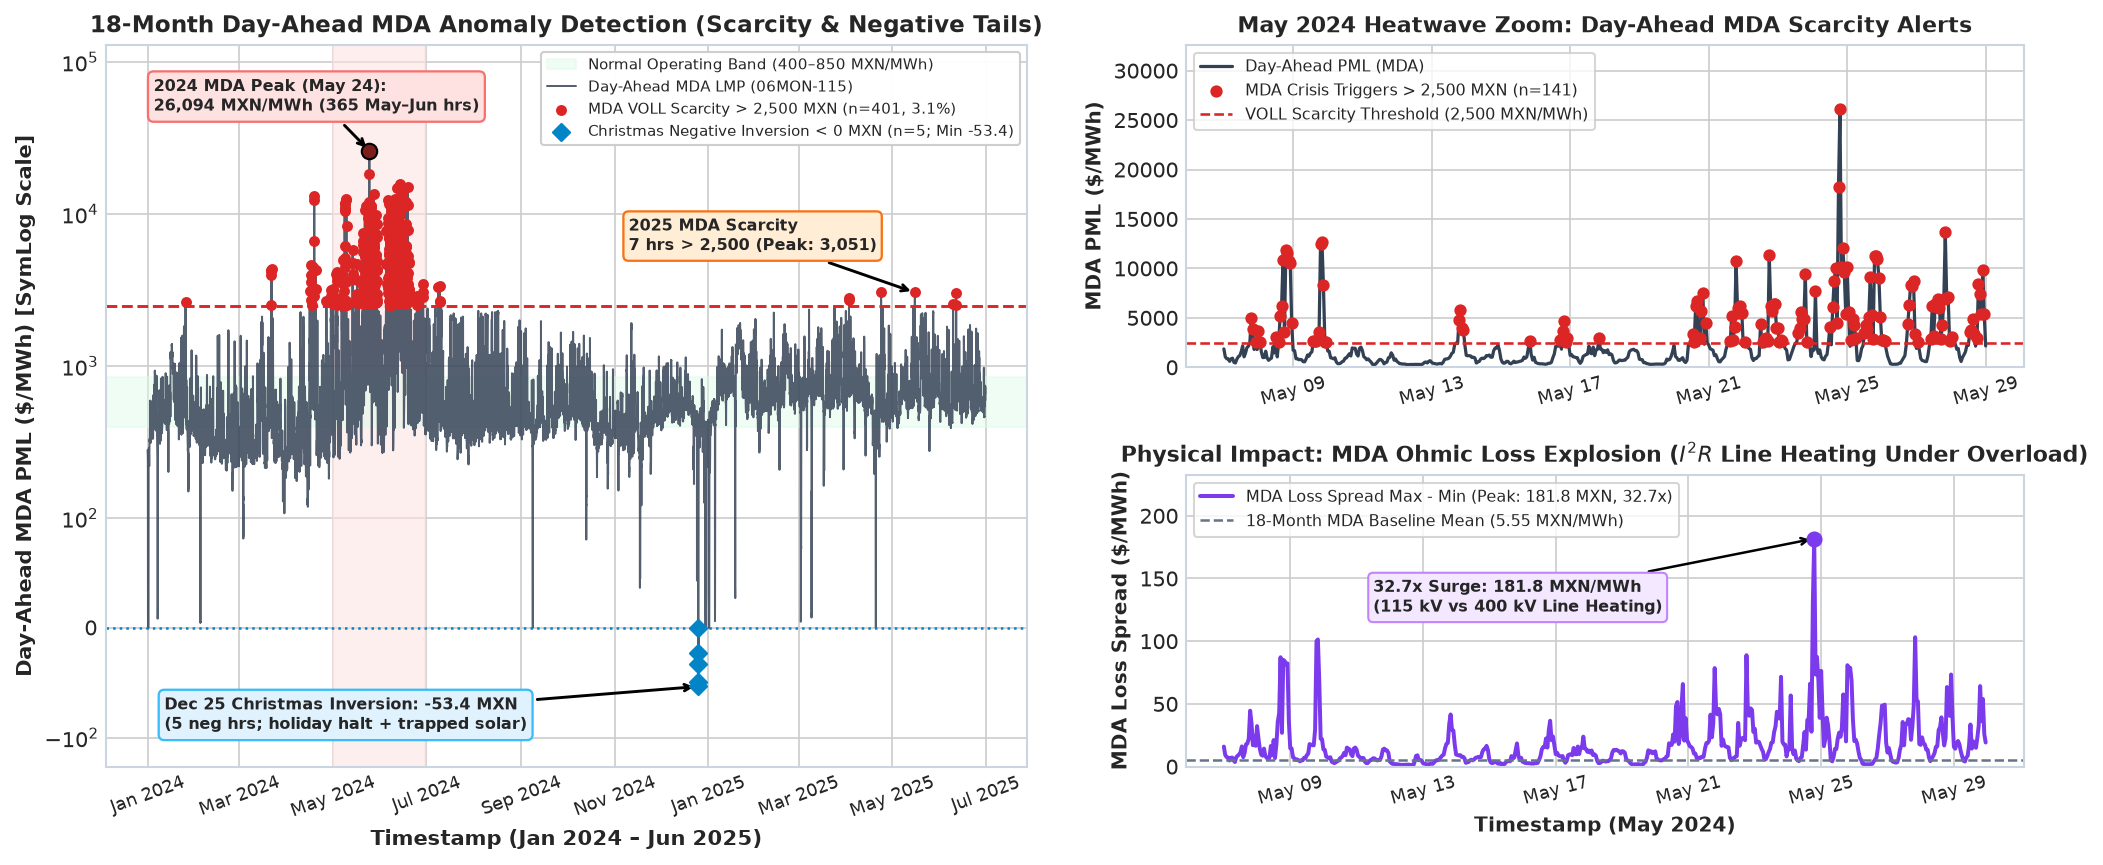

In [9]:
mon_all = df[df['clv_nodo'] == '06MON-115'].sort_values('timestamp').copy()
mon_all['upper_mda'] = mon_all['pml_mda'] > 2500.0
mon_all['neg_mda'] = mon_all['pml_mda'] < 0.0

# MDA-only physical I^2R loss spread series across all 9 Monclova nodes
loss_piv_mda = df.pivot(index='timestamp', columns='clv_nodo', values='pml_per_mda')
loss_spread_mda = loss_piv_mda.max(axis=1) - loss_piv_mda.min(axis=1)
loss_mean_mda = float(loss_spread_mda.mean())

n_mj_mda = int((mon_all['upper_mda'] & mon_all['timestamp'].between('2024-05-01', '2024-06-30 23:00')).sum())
sub25_mda = mon_all[mon_all['timestamp'] >= '2025-01-01']
n_25_mda = int(sub25_mda['upper_mda'].sum())
pk_25_mda = sub25_mda.loc[sub25_mda['pml_mda'].idxmax()]

print(f"All-Zone MDA Peaks -> Max: ${df['pml_mda'].max():,.2f} | 2025 Max: ${df[df['timestamp']>='2025-01-01']['pml_mda'].max():,.2f} | Min: ${df['pml_mda'].min():.2f}")
print(f"MDA Alerts (06MON-115): {int(mon_all['upper_mda'].sum())} upper (>$2500, {mon_all['upper_mda'].mean()*100:.2f}% rate), "
      f"{int(mon_all['neg_mda'].sum())} negative inversion (<$0, min=${mon_all['pml_mda'].min():.2f}) | "
      f"May-Jun 24={n_mj_mda} ({n_mj_mda/mon_all['upper_mda'].sum()*100:.1f}%), 2025={n_25_mda} (2025 peak=${pk_25_mda['pml_mda']:.2f})")
print(f"MDA Loss Spread -> Mean: ${loss_mean_mda:.2f}/MWh | Peak: ${loss_spread_mda.max():.2f}/MWh ({loss_spread_mda.max()/loss_mean_mda:.1f}x) | "
      f"Min node pml_per_mda: ${df['pml_per_mda'].min():.2f}/MWh")

# Build dual-grid executive Slide 10 visual (MDA-only, matching 10.65 x 4.45 / 16.5 x 6.25 ratio)
fig = plt.figure(figsize=(16.5, 6.25))
gs = fig.add_gridspec(2, 2, width_ratios=[1.1, 1.0], height_ratios=[1.05, 0.95], hspace=0.35, wspace=0.18)
ax_macro = fig.add_subplot(gs[:, 0])
ax_zoom = fig.add_subplot(gs[0, 1])
ax_loss = fig.add_subplot(gs[1, 1])

# Left Macro Panel: Day-Ahead MDA 18M (symlog reveals -$53.4 Christmas inversion alongside +26,094 peak)
ax_macro.axvspan(pd.Timestamp('2024-05-01'), pd.Timestamp('2024-06-30'), color='#FEE2E2', alpha=0.55)
ax_macro.axhspan(400, 850, color='#DCFCE7', alpha=0.45, label='Normal Operating Band (400–850 MXN/MWh)')
ax_macro.plot(mon_all['timestamp'], mon_all['pml_mda'], color='#334155', lw=0.95, alpha=0.84, label='Day-Ahead MDA LMP (06MON-115)')

anom_mda = mon_all[mon_all['upper_mda']]
ax_macro.scatter(anom_mda['timestamp'], anom_mda['pml_mda'], color='#DC2626', s=18, zorder=5,
                 label=f'MDA VOLL Scarcity > 2,500 MXN (n={len(anom_mda)}, {len(anom_mda)/len(mon_all)*100:.1f}%)')
ax_macro.axhline(2500, color='#DC2626', ls='--', lw=1.4)

neg_mda = mon_all[mon_all['neg_mda']]
min_mda = mon_all.loc[mon_all['pml_mda'].idxmin()]
ax_macro.scatter(neg_mda['timestamp'], neg_mda['pml_mda'], color='#0284C7', s=34, zorder=6, marker='D',
                 label=f'Christmas Negative Inversion < 0 MXN (n={len(neg_mda)}; Min {min_mda["pml_mda"]:.1f})')
ax_macro.axhline(0, color='#0284C7', ls=':', lw=1.2)

pk_mda = mon_all.loc[mon_all['pml_mda'].idxmax()]
ax_macro.scatter([pk_mda['timestamp']], [pk_mda['pml_mda']], color='#7F1D1D', s=55, zorder=6, edgecolors='black')
ax_macro.annotate(
    f"2024 MDA Peak ({pk_mda['timestamp'].strftime('%b %d')}):\n{pk_mda['pml_mda']:,.0f} MXN/MWh ({n_mj_mda} May–Jun hrs)",
    xy=(pk_mda['timestamp'], pk_mda['pml_mda']), xytext=(pd.Timestamp('2024-01-05'), 48000),
    bbox=dict(boxstyle='round,pad=0.35', facecolor='#FEE2E2', edgecolor='#F87171', lw=1.1),
    arrowprops=dict(arrowstyle='->', color='black', lw=1.4), fontsize=7.8, fontweight='bold'
)
ax_macro.annotate(
    f"2025 MDA Scarcity\n{n_25_mda} hrs > 2,500 (Peak: {pk_25_mda['pml_mda']:,.0f})",
    xy=(pk_25_mda['timestamp'], pk_25_mda['pml_mda']), xytext=(pd.Timestamp('2024-11-10'), 5800),
    bbox=dict(boxstyle='round,pad=0.32', facecolor='#FFEDD5', edgecolor='#F97316', lw=1.1),
    arrowprops=dict(arrowstyle='->', color='black', lw=1.4), fontsize=7.8, fontweight='bold'
)
ax_macro.annotate(
    f"Dec 25 Christmas Inversion: {min_mda['pml_mda']:.1f} MXN\n(5 neg hrs; holiday halt + trapped solar)",
    xy=(min_mda['timestamp'], min_mda['pml_mda']), xytext=(pd.Timestamp('2024-01-12'), -92),
    bbox=dict(boxstyle='round,pad=0.35', facecolor='#E0F2FE', edgecolor='#38BDF8', lw=1.1),
    arrowprops=dict(arrowstyle='->', color='black', lw=1.4), fontsize=7.8, fontweight='bold'
)

ax_macro.set_yscale('symlog', linthresh=100, linscale=0.65)
ax_macro.set_ylim(-155, 130000)
ax_macro.set_ylabel('Day-Ahead MDA PML ($/MWh) [SymLog Scale]', fontsize=10, fontweight='bold')
ax_macro.set_xlabel('Timestamp (Jan 2024 – Jun 2025)', fontsize=10, fontweight='bold')
ax_macro.set_title('18-Month Day-Ahead MDA Anomaly Detection (Scarcity & Negative Tails)', fontsize=11, fontweight='bold')
ax_macro.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax_macro.tick_params(axis='x', rotation=20, labelsize=8.5)
ax_macro.legend(loc='upper right', fontsize=7.1, frameon=True, facecolor='white', framealpha=0.96)

# Top-Right Zoom: May 2024 Heatwave (MDA Only)
hw = mon_all[(mon_all['timestamp'] >= '2024-05-07') & (mon_all['timestamp'] <= '2024-05-29')]
hw_anom = hw[hw['upper_mda']]
ax_zoom.plot(hw['timestamp'], hw['pml_mda'], color='#334155', lw=1.55, label='Day-Ahead PML (MDA)')
ax_zoom.scatter(hw_anom['timestamp'], hw_anom['pml_mda'], color='#DC2626', s=24, zorder=5,
                label=f'MDA Crisis Triggers > 2,500 MXN (n={len(hw_anom)})')
ax_zoom.axhline(2500, color='#DC2626', ls='--', lw=1.25, label='VOLL Scarcity Threshold (2,500 MXN/MWh)')
ax_zoom.set_ylim(0, hw['pml_mda'].max() * 1.25)
ax_zoom.set_ylabel('MDA PML ($/MWh)', fontsize=9.5, fontweight='bold')
ax_zoom.set_title('May 2024 Heatwave Zoom: Day-Ahead MDA Scarcity Alerts', fontsize=10.5, fontweight='bold')
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax_zoom.tick_params(axis='x', rotation=15, labelsize=8.5)
ax_zoom.legend(loc='upper left', fontsize=7.7, frameon=True, facecolor='white')

# Bottom-Right Zoom: Physical I^2R Loss Surge (MDA Only)
l_sub_mda = loss_spread_mda.loc['2024-05-07':'2024-05-29']
pk_ls_ts = l_sub_mda.idxmax()
pk_ls_val = float(l_sub_mda.max())
ax_loss.plot(l_sub_mda.index, l_sub_mda.values, color='#7C3AED', lw=1.9,
             label=f'MDA Loss Spread Max - Min (Peak: {pk_ls_val:.1f} MXN, {pk_ls_val/loss_mean_mda:.1f}x)')
ax_loss.axhline(loss_mean_mda, color='#64748B', ls='--', lw=1.2,
                label=f'18-Month MDA Baseline Mean ({loss_mean_mda:.2f} MXN/MWh)')
ax_loss.scatter([pk_ls_ts], [pk_ls_val], color='#7C3AED', s=45, zorder=5)
ax_loss.annotate(
    f"{pk_ls_val/loss_mean_mda:.1f}x Surge: {pk_ls_val:.1f} MXN/MWh\n(115 kV vs 400 kV Line Heating)",
    xy=(pk_ls_ts, pk_ls_val), xytext=(pd.Timestamp('2024-05-11 12:00'), pk_ls_val * 0.68),
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#F3E8FF', edgecolor='#C084FC', lw=1.0),
    arrowprops=dict(arrowstyle='->', color='black', lw=1.2), fontsize=7.9, fontweight='bold'
)
ax_loss.set_ylim(0, pk_ls_val * 1.28)
ax_loss.set_ylabel('MDA Loss Spread ($/MWh)', fontsize=9.5, fontweight='bold')
ax_loss.set_xlabel('Timestamp (May 2024)', fontsize=9.5, fontweight='bold')
ax_loss.set_title('Physical Impact: MDA Ohmic Loss Explosion ($I^2 R$ Line Heating Under Overload)', fontsize=10.5, fontweight='bold')
ax_loss.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax_loss.tick_params(axis='x', rotation=15, labelsize=8.5)
ax_loss.legend(loc='upper left', fontsize=7.8, frameon=True, facecolor='white')

plt.savefig(FIG_DIR / 'slide_11_anomaly_detection.png', dpi=200, bbox_inches='tight')
plt.show()


## Summary of Generated Presentation Assets (`experiments/figures/`)
All figures and metrics above are strictly synchronized to the **3-model causal Real-Time (`MTR`) benchmark**:
- `SARIMA(1,0,1)x(1,0,1,24)`: `MAE = $134.22/MWh | WAPE = 17.7% | R² = 0.559 | Prec(<=100) = 68.3%`
- `Ridge Regression (L2)`: `MAE = $142.65/MWh | WAPE = 18.8% | R² = 0.568 | Prec(<=100) = 57.4%`
- **`HistGBDT (L1 MAE Loss)`**: **`MAE = $101.10/MWh | WAPE = 13.3% | R² = 0.615 | Prec(<=100) = 79.9%`**
